In [1]:
# # Session 10.4 — Boxplot & Violin Plot (Outlier Visualization)
# # આજે આપણે Seaborn માં Boxplot અને Violin Plot શીખીશું. Data Science માં આ plots નો ઉપયોગ data spread સમજવા, અલગ groups ની સરખામણી કરવા અને અસામાન્ય values એટલે કે potential outliers શોધવા માટે થાય છે.
# # 1. આજના learning objectives
# # - sns.boxplot() દ્વારા Median, Quartiles અને Whiskers સમજવા.
# # - sns.violinplot() દ્વારા distribution નો આકાર સમજવો.
# # - IQR formula નો ઉપયોગ કરીને potential outliers શોધવા.
# # - Student marks અને business sales પર practical કરવું.
# # - બંને charts વચ્ચેનો તફાવત સમજવો.
# # 2. Boxplot શું છે?

# oxplot ને Box-and-Whisker Plot પણ કહે છે. તે numerical data નો spread અને quartiles દર્શાવે છે.

# મુખ્ય ભાગો:
# - Q1: 25th percentile.
# - Median (Q2): 50th percentile.
# - Q3: 75th percentile.
# - IQR: Q3 અને Q1 વચ્ચેનો તફાવત.
# - Whiskers: સામાન્ય રીતે IQR rule ની અંદર આવતી સૌથી દૂરની observations સુધી પહોંચે છે.
# - Outlier markers: Whiskers બહારની observations દર્શાવી શકે છે.

# IQR = Q3 - Q1 

# potential outliers find 

# lower bound = Q1 - 1.5(IQR)
# upper bound = Q3 + 1.5(IQR)


In [2]:
# 3. Practical Setup — VS Code / Jupyter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = {
    "Student": [
        "Amit", "Neha", "Ravi", "Pooja", "Karan",
        "Meera", "Jay", "Priya", "Rahul", "Nisha"
    ],
    "Department": [
        "IT", "IT", "Computer", "Computer", "IT",
        "Computer", "IT", "Computer", "IT", "Computer"
    ],
    "Python": [85, 92, 70, 88, 65, 95, 78, 82, 90, 86],
    "SQL": [78, 88, 75, 90, 68, 92, 80, 85, 84, 89]
}

df = pd.DataFrame(data)

print(df)

  Student Department  Python  SQL
0    Amit         IT      85   78
1    Neha         IT      92   88
2    Ravi   Computer      70   75
3   Pooja   Computer      88   90
4   Karan         IT      65   68
5   Meera   Computer      95   92
6     Jay         IT      78   80
7   Priya   Computer      82   85
8   Rahul         IT      90   84
9   Nisha   Computer      86   89


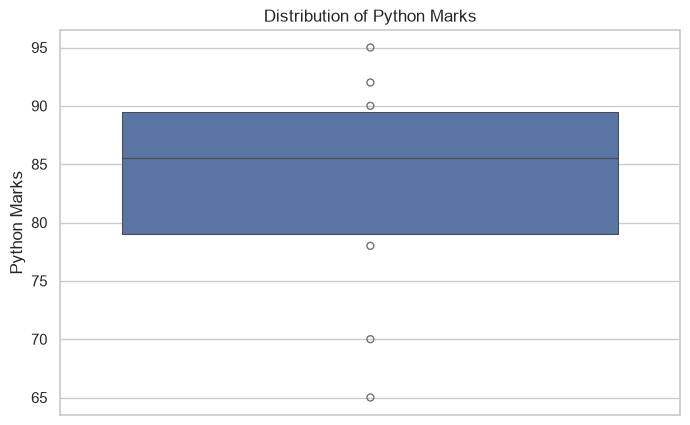

In [ ]:
# 4. Practical 1 — Basic Boxplot

plt.figure(figsize=(8,5))

sns.boxenplot(data=df,y="Python")
plt.title("Distribution of Python Marks")
plt.ylabel("Python Marks")
plt.show()

# Box ની અંદરની રેખા Median બતાવે છે.
# Box ની નીચલી અને ઉપરની બાજુ Q1 અને Q3 દર્શાવે છે.
# Whiskers સામાન્ય રીતે outlier limits ની અંદરની સૌથી દૂરની values સુધી પહોંચે છે.
# અલગ દેખાતા points potential outliers હોઈ શકે છે.

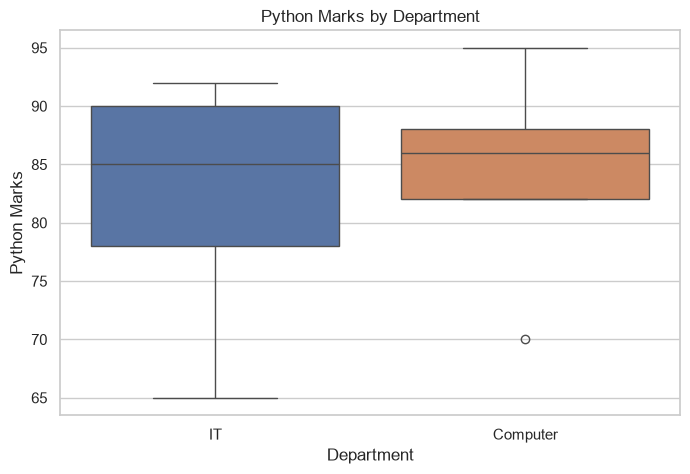

In [4]:
# 5. Practical 2 — Department પ્રમાણે સરખામણી

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Department",
    y="Python",
    hue="Department"
)

plt.title("Python Marks by Department")
plt.xlabel("Department")
plt.ylabel("Python Marks")
plt.show()

In [ ]:
# 6. Practical 3 — IQR વડે Potential Outliers શોધો
# હવે Python વડે bounds ની બહાર આવતી values શોધીએ.

Q1 = df["Python"].quantile(0.25) # Q1 શોધે છે
Q3 = df["Python"].quantile(0.75) #Q3 શોધે છે

IQR = Q3 - Q1 #IQR ગણે છે

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df["Python"] < lower_bound) |
    (df["Python"] > upper_bound) 
]

print("\nPotential Outliers:")
print(outliers)

Q1: 79.0
Q3: 89.5
IQR: 10.5
Lower Bound: 63.25
Upper Bound: 105.25

Potential Outliers:
Empty DataFrame
Columns: [Student, Department, Python, SQL]
Index: []


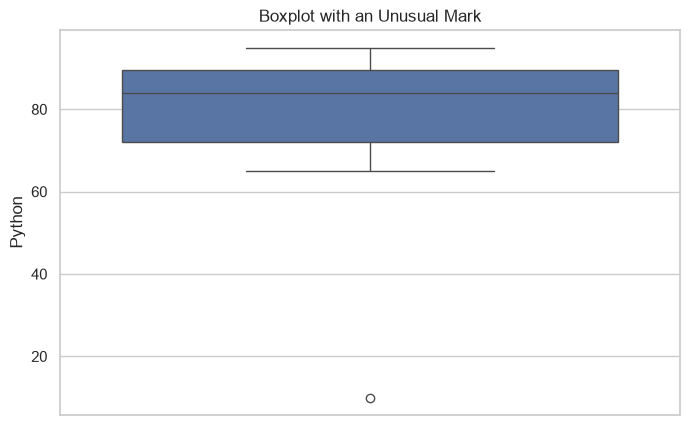

In [6]:
# હાલના dataset માં potential outliers ન પણ મળે. હવે test માટે એક અસામાન્ય value ઉમેરીએ.
df_test = df.copy()

df_test.loc[0, "Python"] = 10

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_test, y="Python")

plt.title("Boxplot with an Unusual Mark")
plt.show()

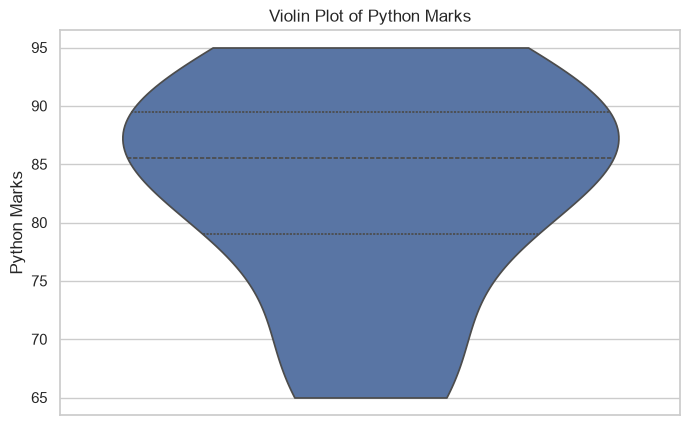

In [ ]:
# 7. Practical 4 — Violin Plot

plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    y="Python",
    inner="quartile", #અંદર quartile lines દર્શાવે છે.
    cut=0 # KDE oversedta data rage outside show stop kare
)

plt.title("Violin Plot of Python Marks")
plt.ylabel("Python Marks")
plt.show()

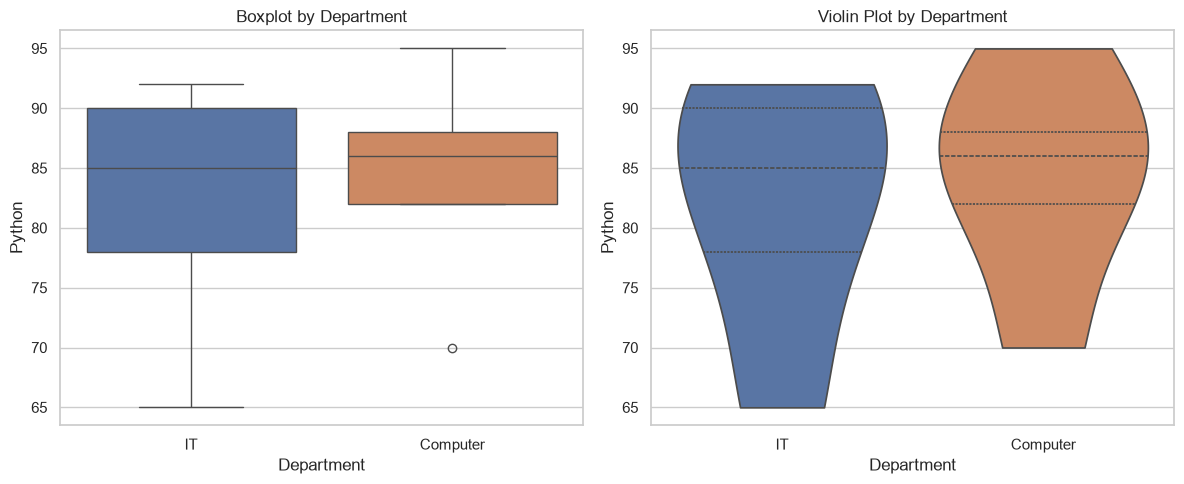

In [8]:
# 8. Practical 5 — Boxplot અને Violin Plot ની સરખામણી
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="Department",
    y="Python",
    hue="Department",
    ax=ax[0]
)
ax[0].set_title("Boxplot by Department")

sns.violinplot(
    data=df,
    x="Department",
    y="Python",
    hue="Department",
    inner="quartile",
    cut=0,
    ax=ax[1]
)
ax[1].set_title("Violin Plot by Department")

plt.tight_layout()
plt.show()

In [9]:
# Feature	Boxplot	Violin Plot
# Median અને quartiles	સ્પષ્ટ રીતે બતાવે છે	inner="quartile" સાથે બતાવે છે
# Data spread	હા	હા
# Distribution નો આકાર	સ્પષ્ટ રીતે નહીં	હા
# Outlier markers	સામાન્ય રીતે દર્શાવે છે	મુખ્યત્વે density નો આકાર દર્શાવે છે
# ઉપયોગ	Summary અને outlier તપાસ	Distribution ના shape ની સરખામણી

In [10]:
# 9. Practical 6 — Business Sales માં Outliers

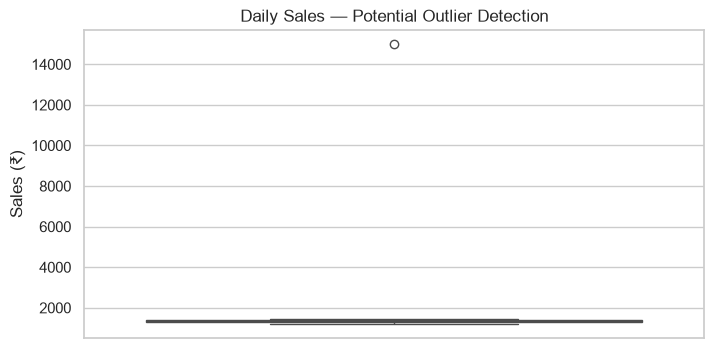

In [11]:

sales_df = pd.DataFrame({
    "Day": list(range(1, 11)),
    "Sales": [
        1200, 1350, 1280, 1400, 1320,
        1250, 1380, 1300, 1450, 15000
    ]
})

plt.figure(figsize=(8, 4))

sns.boxplot(data=sales_df, y="Sales")

plt.title("Daily Sales — Potential Outlier Detection")
plt.ylabel("Sales (₹)")
plt.show()

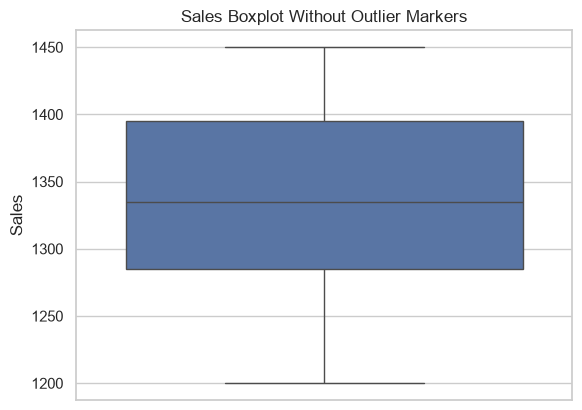

In [12]:
sns.boxplot(
    data=sales_df,
    y="Sales",
    showfliers=False
)

plt.title("Sales Boxplot Without Outlier Markers")
plt.show()

In [ ]:
# 12. Homework / Assignment
# Assignment Progress
# 0/7 પૂર્ણ

# [ ] Python marks માટે Boxplot બનાવો.
# [ ] Department પ્રમાણે Median અને spread સરખાવો.
# [ ] IQR, lower bound અને upper bound calculate કરો.
# [ ] Potential outliers Python code વડે શોધો.
# [ ] Violin Plot માં inner='quartile' અને cut=0 વાપરો.
# [ ] Sales data માં unusual value ઉમેરી તેનું analysis કરો.
# [ ] Charts પરથી 3 observations લખો.
